# Predicting diabetes: an end-to-end MLflow example (Unity Catalog)

This notebook adapts the Databricks tutorial [Training machine learning models on tabular data: an end-to-end example (Unity Catalog)](https://docs.databricks.com/aws/en/mlflow/end-to-end-example) to the [Diabetes Health Indicators dataset](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset): 253K responses to the CDC's 2015 Behavioral Risk Factor Surveillance System (BRFSS) survey.

It follows the same steps as the original:
- Load the data into a Delta table and explore it, using **Spark** for the full-size aggregations
- Train a baseline model and track it with MLflow
- Register the model in Unity Catalog and give it the `Champion` alias
- Run a hyperparameter sweep to train a better model
- Promote the best model, then score all 253K rows in parallel with a Spark UDF

**The task:** predict whether a survey respondent has diabetes or prediabetes (`Diabetes_binary` = 1) from 21 answers about health, habits and demographics.

## Requirements
- **classic cluster** running **Databricks Runtime 15.4 LTS ML or above** (the ML runtime includes scikit-learn, XGBoost and MLflow).
- A workspace with **Unity Catalog** enabled, and `USE CATALOG`, `USE SCHEMA`, `CREATE TABLE` and `CREATE MODEL` privileges on the catalog and schema you choose below.
- The file `diabetes_binary_health_indicators_BRFSS2015.csv` from the Kaggle dataset, uploaded to a **Unity Catalog volume** (recommended) or next to this notebook.

# Install libraries

- Optuna is used to find the best hyper-parameters for a given model.
- Seaborn is used for statistical visualizations
- xgboost is a machine learning library

In [0]:
%pip install optuna seaborn xgboost

In [0]:
dbutils.library.restartPython()

# Unity Catalog Set Up

In [0]:
import mlflow

dbutils.widgets.text("catalog_name", "ccozad_experiments", "Catalog")
dbutils.widgets.text("schema_name", "default", "Schema")
dbutils.widgets.text("csv_path", "diabetes_binary_health_indicators_BRFSS2015.csv", "CSV path")

CATALOG_NAME = dbutils.widgets.get("catalog_name")
SCHEMA_NAME = dbutils.widgets.get("schema_name")
CSV_PATH = dbutils.widgets.get("csv_path")

mlflow.set_registry_uri("databricks-uc")
model_name = f"{CATALOG_NAME}.{SCHEMA_NAME}.diabetes_risk"
raw_table = f"{CATALOG_NAME}.{SCHEMA_NAME}.diabetes_brfss2015"
scored_table = f"{CATALOG_NAME}.{SCHEMA_NAME}.diabetes_brfss2015_scored"
print(f"Raw table:    {raw_table}\nScored table: {scored_table}\nModel:        {model_name}")

# Read the data into a Delta table

In [0]:
import numpy as np
import pandas as pd
from pyspark.sql import functions as F

if CSV_PATH.startswith(("/Volumes/", "dbfs:/", "s3://", "abfss://", "gs://")):
    sdf_raw = spark.read.csv(CSV_PATH, header=True, inferSchema=True)
else:
    sdf_raw = spark.createDataFrame(pd.read_csv(CSV_PATH))

TARGET = "Diabetes_binary"
sdf_raw = sdf_raw.select([F.col(c).cast("double").alias(c) for c in sdf_raw.columns])

(sdf_raw.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", True)
    .saveAsTable(raw_table))

sdf = spark.table(raw_table)
FEATURES = [c for c in sdf.columns if c != TARGET]
print(f"{sdf.count():,} rows, {len(FEATURES)} features")
display(sdf.limit(5))

253,680 rows, 21 features


Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
1.0,0.0,1.0,1.0,25.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,3.0,0.0,0.0,0.0,0.0,11.0,5.0,5.0
0.0,1.0,0.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,4.0,6.0,8.0
0.0,0.0,0.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,2.0,0.0,0.0,0.0,0.0,8.0,6.0,8.0
0.0,1.0,1.0,1.0,21.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,4.0,30.0,15.0,0.0,0.0,7.0,4.0,2.0
0.0,1.0,1.0,1.0,27.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,2.0,0.0,0.0,0.0,10.0,6.0,7.0


# Explore the data with Spark

In [0]:
n_rows = sdf.count()
quality = sdf.select(
    *[F.sum(F.col(c).isNull().cast("int")).alias(c) for c in sdf.columns]
).toPandas().T.rename(columns={0: "missing"})
print(f"Columns with missing values: {int((quality['missing'] > 0).sum())}")

n_distinct = sdf.dropDuplicates().count()
print(f"Exact duplicate rows: {n_rows - n_distinct:,} ({(n_rows - n_distinct) / n_rows:.1%})")

display(sdf.select(FEATURES).summary("min", "25%", "50%", "75%", "max"))

Columns with missing values: 0
Exact duplicate rows: 24,206 (9.5%)


summary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
min,0.0,0.0,0.0,12.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
25%,0.0,0.0,1.0,24.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,6.0,4.0,5.0
50%,0.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,7.0
75%,1.0,1.0,1.0,31.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,3.0,2.0,3.0,0.0,1.0,10.0,6.0,8.0
max,1.0,1.0,1.0,98.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,5.0,30.0,30.0,1.0,1.0,13.0,6.0,8.0


We'll keep repeats because many yes/no columns could have the same responses.

# Target Visualization

In [0]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
BLUE = "#2a78d6"

label_counts = sdf.groupBy(TARGET).count().orderBy(TARGET).toPandas()
label_counts["share"] = label_counts["count"] / label_counts["count"].sum()
display(label_counts)
prevalence = float(label_counts.loc[label_counts[TARGET] == 1, "share"].iloc[0])
print(f"Prevalence of diabetes or prediabetes: {prevalence:.1%}")

Diabetes_binary,count,share
0.0,218334,0.8606669820245979
1.0,35346,0.13933301797540207


Prevalence of diabetes or prediabetes: 13.9%


About 14% of the dataset has diabetes.

# Continious Feature Visualization

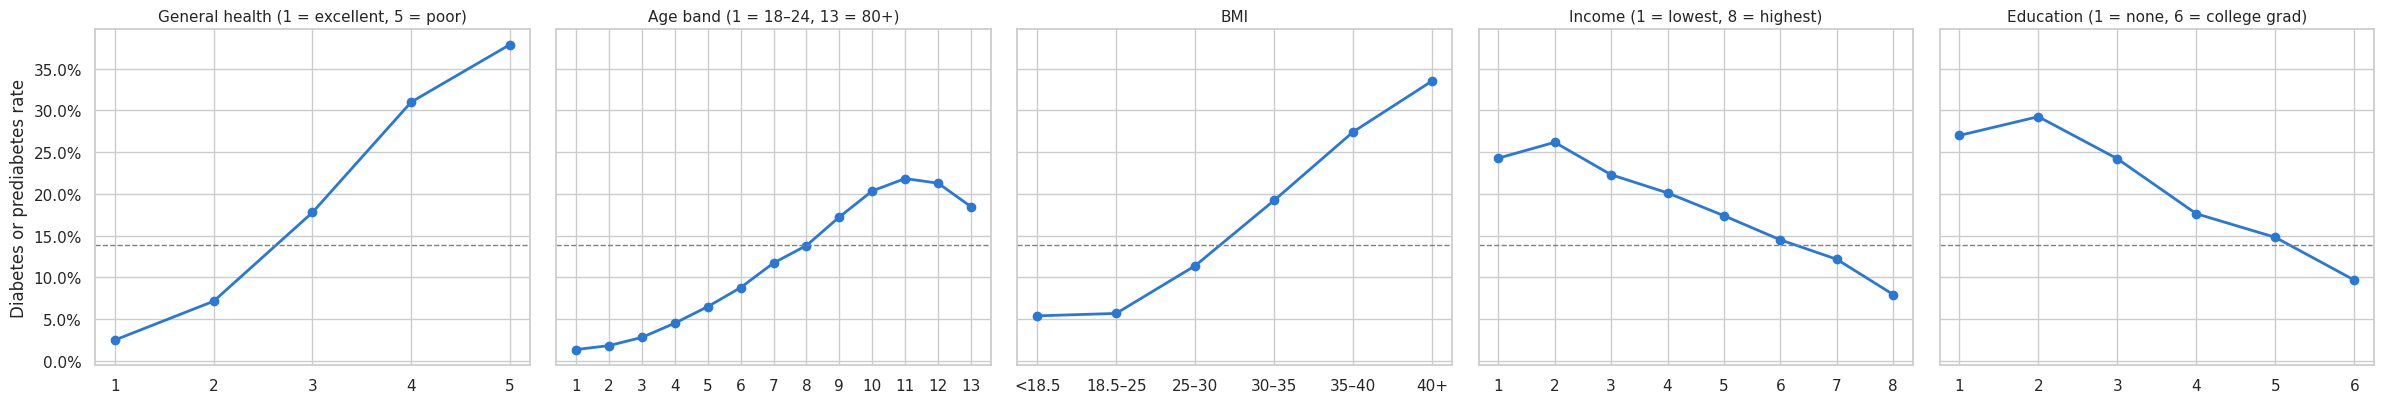

In [0]:
def rate_by(col_expr, name):
    return (sdf.groupBy(col_expr.alias(name))
               .agg(F.avg(TARGET).alias("diabetes_rate"), F.count("*").alias("n"))
               .orderBy(name)
               .toPandas())

bmi_band = (F.when(F.col("BMI") < 18.5, "<18.5")
             .when(F.col("BMI") < 25, "18.5–25")
             .when(F.col("BMI") < 30, "25–30")
             .when(F.col("BMI") < 35, "30–35")
             .when(F.col("BMI") < 40, "35–40")
             .otherwise("40+"))

panels = [
    ("GenHlth", F.col("GenHlth"), "General health (1 = excellent, 5 = poor)"),
    ("Age", F.col("Age"), "Age band (1 = 18–24, 13 = 80+)"),
    ("BMI band", bmi_band, "BMI"),
    ("Income", F.col("Income"), "Income (1 = lowest, 8 = highest)"),
    ("Education", F.col("Education"), "Education (1 = none, 6 = college grad)"),
]

fig, axes = plt.subplots(1, len(panels), figsize=(24, 4.2), sharey=True)
for ax, (name, expr, title) in zip(axes, panels):
    rates = rate_by(expr, name)
    if name == "BMI band":
        order = ["<18.5", "18.5–25", "25–30", "30–35", "35–40", "40+"]
        rates = rates.set_index(name).loc[order].reset_index()
        x_labels = rates[name]
    else:
        x_labels = rates[name].astype(int).astype(str)
    ax.plot(x_labels, rates["diabetes_rate"], marker="o", color=BLUE, linewidth=2)
    ax.axhline(prevalence, color="gray", linestyle="--", linewidth=1)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(None)
axes[0].set_ylabel("Diabetes or prediabetes rate")
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

# Binary Feature Visualization

question,share answering yes,rate if yes,rate if no,ratio (yes / no)
HvyAlcoholConsump,0.056,0.058,0.144,0.405
PhysActivity,0.757,0.116,0.211,0.549
Veggies,0.811,0.13,0.18,0.722
Fruits,0.634,0.129,0.158,0.814
Sex,0.44,0.152,0.13,1.169
AnyHealthcare,0.951,0.141,0.115,1.228
NoDocbcCost,0.084,0.175,0.136,1.288
Smoker,0.443,0.163,0.121,1.352
Stroke,0.041,0.318,0.132,2.409
HighChol,0.424,0.22,0.08,2.758


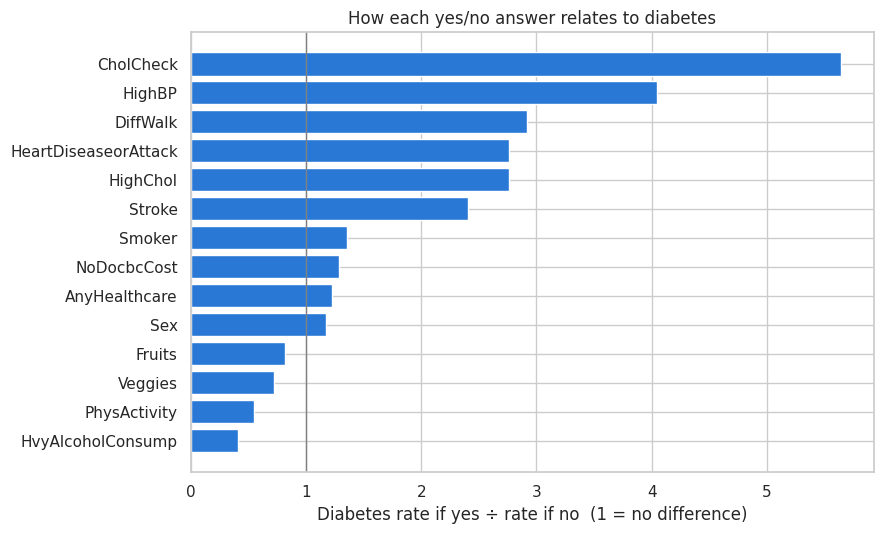

In [0]:
BINARY_FEATURES = [c for c in FEATURES if c not in ("BMI", "GenHlth", "MentHlth", "PhysHlth", "Age", "Education", "Income")]

aggs = []
for c in BINARY_FEATURES:
    aggs += [
        F.avg(F.when(F.col(c) == 1, F.col(TARGET))).alias(f"{c}__yes"),
        F.avg(F.when(F.col(c) == 0, F.col(TARGET))).alias(f"{c}__no"),
        F.avg(F.col(c)).alias(f"{c}__share_yes"),
    ]
row = sdf.agg(*aggs).first().asDict()

binary_rates = pd.DataFrame([
    {"question": c, "share answering yes": row[f"{c}__share_yes"],
     "rate if yes": row[f"{c}__yes"], "rate if no": row[f"{c}__no"]}
    for c in BINARY_FEATURES
])
binary_rates["ratio (yes / no)"] = binary_rates["rate if yes"] / binary_rates["rate if no"]
binary_rates = binary_rates.sort_values("ratio (yes / no)")
display(binary_rates.round(3))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(binary_rates["question"], binary_rates["ratio (yes / no)"], color=BLUE)
ax.axvline(1, color="gray", linewidth=1)
ax.set_xlabel("Diabetes rate if yes ÷ rate if no  (1 = no difference)")
ax.set_title("How each yes/no answer relates to diabetes")
plt.tight_layout()
plt.show()

Commentary: A cholesterol check does not cause diabetes but people going to the doctor often to have their cholesterol checked as part of a normal diagnostics.

# Leakage Check

Make sure a feature does not give away the target value.

In [0]:
from sklearn.metrics import roc_auc_score

pdf = sdf.toPandas()
single_feature_auc = pd.Series(
    {c: roc_auc_score(pdf[TARGET], pdf[c]) for c in FEATURES}
).apply(lambda a: max(a, 1 - a)).sort_values(ascending=False)
display(single_feature_auc.round(3).rename_axis("feature").reset_index(name="AUC on its own"))

feature,AUC on its own
GenHlth,0.73
BMI,0.688
HighBP,0.688
Age,0.647
HighChol,0.643
Income,0.632
DiffWalk,0.618
PhysHlth,0.613
Education,0.594
HeartDiseaseorAttack,0.575


No apparent leakage, we can use all features

# Prep for Baseline Model

In [0]:
from sklearn.model_selection import train_test_split

X = pdf[FEATURES]
y = pdf[TARGET].astype(int)

X_train, X_rem, y_train, y_rem = train_test_split(X, y, train_size=0.6, random_state=123, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_rem, y_rem, test_size=0.5, random_state=123, stratify=y_rem)

for name, part in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:10} {len(part):7,} rows, positive rate {part.mean():.1%}")

train      152,208 rows, positive rate 13.9%
validation  50,736 rows, positive rate 13.9%
test        50,736 rows, positive rate 13.9%


# Train the Baseline Model

In [0]:
import time

import mlflow.pyfunc
import sklearn
from mlflow.models.signature import infer_signature
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score


class ProbabilityModelWrapper(mlflow.pyfunc.PythonModel):
    """Returns P(diabetes or prediabetes) from a fitted classifier."""

    def __init__(self, model):
        self.model = model

    def predict(self, context, model_input, params=None):
        return self.model.predict_proba(model_input)[:, 1]


def log_pyfunc_model(model, artifact_name, extra_pip=()):
    wrapped = ProbabilityModelWrapper(model)
    signature = infer_signature(X_train.head(1000), wrapped.predict(None, X_train.head(1000)))
    return mlflow.pyfunc.log_model(
        artifact_name,
        python_model=wrapped,
        signature=signature,
        input_example=X_train.head(3),
        pip_requirements=[f"scikit-learn=={sklearn.__version__}", f"mlflow=={mlflow.__version__}", *extra_pip],
    )


def val_metrics(proba):
    return {"val_auc": roc_auc_score(y_val, proba), "val_avg_precision": average_precision_score(y_val, proba)}


with mlflow.start_run(run_name="untuned_random_forest") as rf_run:
    rf_params = {"n_estimators": 200, "min_samples_leaf": 50, "max_features": "sqrt"}
    rf = RandomForestClassifier(**rf_params, n_jobs=-1, random_state=123)
    rf.fit(X_train, y_train)

    rf_val = val_metrics(rf.predict_proba(X_val)[:, 1])
    mlflow.log_params(rf_params)
    mlflow.log_metrics(rf_val)
    rf_model_info = log_pyfunc_model(rf, "random_forest_model")

print(f"Random forest  validation AUC {rf_val['val_auc']:.3f}, average precision {rf_val['val_avg_precision']:.3f}")

# Review Learned Feature Importances

In [0]:
feature_importances = pd.DataFrame(rf.feature_importances_, index=FEATURES, columns=["importance"])
display(feature_importances.sort_values("importance", ascending=False).round(3).reset_index(names="feature"))

feature,importance
GenHlth,0.225
HighBP,0.179
BMI,0.168
HighChol,0.093
Age,0.079
DiffWalk,0.073
HeartDiseaseorAttack,0.04
Income,0.033
PhysHlth,0.03
Education,0.015


# Register the Model in Unity Catalog

In [0]:
model_version = mlflow.register_model(rf_model_info.model_uri, model_name)

# Label the current version as Champion

In [0]:
from mlflow.tracking import MlflowClient

client = MlflowClient()
client.set_registered_model_alias(model_name, "Champion", model_version.version)

model = mlflow.pyfunc.load_model(f"models:/{model_name}@Champion")

# Sanity check: this should match the validation AUC logged above
print(f"Champion validation AUC: {roc_auc_score(y_val, model.predict(X_val)):.3f}")

Champion validation AUC: 0.824


# Experiment with a new model

In [0]:
import optuna
import xgboost as xgb

optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS = 30


def make_xgb(params):
    return xgb.XGBClassifier(
        n_estimators=2000,
        early_stopping_rounds=50,
        eval_metric="auc",
        tree_method="hist",
        n_jobs=-1,
        random_state=123,
        **params,
    )


def objective(trial):
    params = {
        "max_depth": trial.suggest_int("max_depth", 3, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 50, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }
    with mlflow.start_run(nested=True, run_name=f"trial_{trial.number}"):
        clf = make_xgb(params)
        clf.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
        metrics = val_metrics(clf.predict_proba(X_val)[:, 1])
        mlflow.log_params(params)
        mlflow.log_metrics({**metrics, "best_iteration": clf.best_iteration})
    return metrics["val_auc"]


with mlflow.start_run(run_name="xgboost_sweep") as sweep_run:
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=123))
    study.optimize(objective, n_trials=N_TRIALS)
    mlflow.log_params({f"best_{k}": v for k, v in study.best_params.items()})
    mlflow.log_metric("best_val_auc", study.best_value)

print(f"Best validation AUC: {study.best_value:.4f}")
print(f"Best parameters: {study.best_params}")

Best validation AUC: 0.8278
Best parameters: {'max_depth': 4, 'learning_rate': 0.02777105769035135, 'subsample': 0.8917465897598927, 'colsample_bytree': 0.5108983825478983, 'min_child_weight': 5.341722657497681, 'reg_lambda': 1.3138001653052775}


# Use MLFlow to view the results

In [0]:
with mlflow.start_run(run_name="xgboost_best") as xgb_run:
    best_xgb = make_xgb(study.best_params)
    best_xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    xgb_val = val_metrics(best_xgb.predict_proba(X_val)[:, 1])
    mlflow.log_params(study.best_params)
    mlflow.log_metrics(xgb_val)
    xgb_model_info = log_pyfunc_model(best_xgb, "xgboost_model", extra_pip=[f"xgboost=={xgb.__version__}"])

comparison = pd.DataFrame([
    {"model": "Random forest (baseline)", **rf_val},
    {"model": "XGBoost (tuned)", **xgb_val},
])
display(comparison.round(4))

# Update the champion

In [0]:
MIN_AUC_GAIN = 0.002

new_model_version = mlflow.register_model(xgb_model_info.model_uri, model_name)

# Registering the model takes a few seconds, so add a small delay
time.sleep(15)

if xgb_val["val_auc"] >= rf_val["val_auc"] + MIN_AUC_GAIN:
    client.set_registered_model_alias(model_name, "Champion", new_model_version.version)
    print(f"Champion is now version {new_model_version.version} (XGBoost).")
else:
    print(f"Champion stays version {model_version.version} (random forest); XGBoost registered as version {new_model_version.version}.")

# Evaluate the new champion

Champion test AUC: 0.834   average precision: 0.441   (random baseline AP = 0.139)


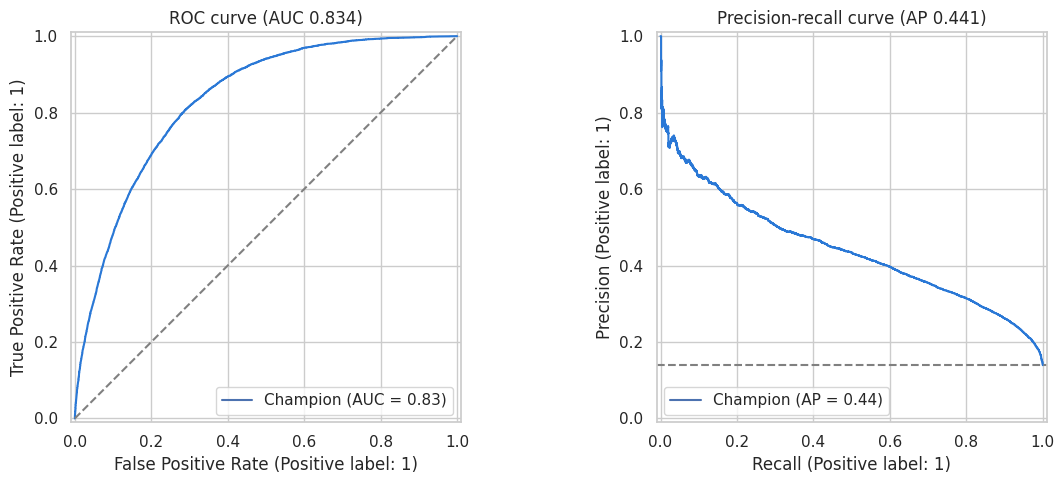

In [0]:
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

champion = mlflow.pyfunc.load_model(f"models:/{model_name}@Champion")
test_proba = np.asarray(champion.predict(X_test))
test_auc = roc_auc_score(y_test, test_proba)
test_ap = average_precision_score(y_test, test_proba)
print(f"Champion test AUC: {test_auc:.3f}   average precision: {test_ap:.3f}   (random baseline AP = {y_test.mean():.3f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_test, test_proba, name="Champion", ax=axes[0])
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_title(f"ROC curve (AUC {test_auc:.3f})")
PrecisionRecallDisplay.from_predictions(y_test, test_proba, name="Champion", ax=axes[1])
axes[1].axhline(y_test.mean(), linestyle="--", color="gray")
for ax in axes:
    ax.get_lines()[0].set_color(BLUE)   # works across scikit-learn versions
axes[1].set_title(f"Precision-recall curve (AP {test_ap:.3f})")
plt.tight_layout()
plt.show()

# Commentary

- We created a baseline model across 253K records and registered that baseline model with Unity Catalog. 
- The baseline was given the alias of `Champion` which allows code to use the best model registered at a given time. 
- We logged experiments to find a better model using ML Flow. 
- Optuna was used to experiment across hyper parameters to find a better configuration. 
- Once we identified a better model we moved the `Champion` alias to point and the best model.
- We tested the new champion to confirm its performance

This workflow models more of way teams work in practice where a new model is only used when it is proven to work better than the best model to date.